# Annotate abundance changes with ClinVar labels

In [2]:
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../..")
from analyses_plot_utils import *
warnings.filterwarnings('ignore')

# Set style
sns.set_style(style='white')
# sns.set_palette("husl")

## 0. Load data

In [3]:
dualipa_outputs = "../3_outputs"
metadata_outputs = "../../../1_allele_collection/1_inputs"
integrative_inputs = "../../../3_integrated_assay_analyses/1_inputs/dual_ipa"
# priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]

# merge scores with metadata
scores = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", separator=",", infer_schema_length=1000000)
scores = scores.with_columns(
    pl.when(pl.col("inheritance_pattern").is_null())
    .then(pl.lit("unknown"))
    .otherwise(pl.col("inheritance_pattern"))
    .alias("inheritance_pattern")
)
hue_order = sorted(scores["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
clinvar_palette_old = palette_dict["clinvar_clnsig_clean"]

## 1. Abudance log2(z-score) dist. in each category

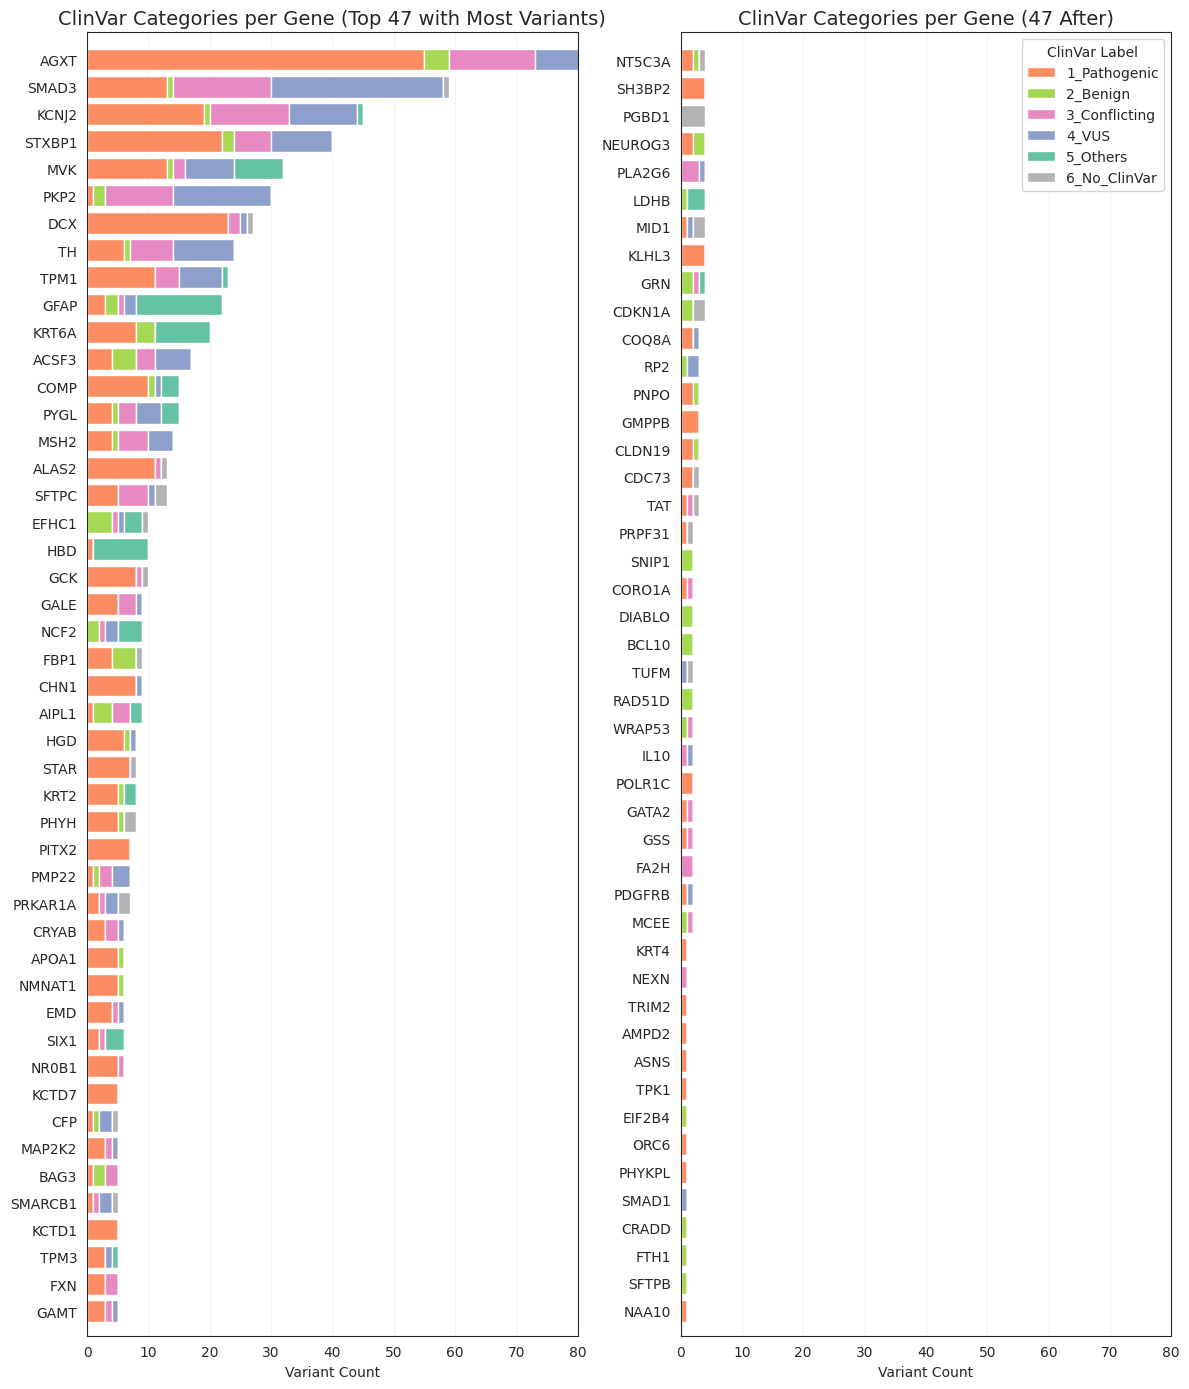

In [9]:
# 2. Count per (gene, category)
top_num = int(np.ceil(scores.unique("symbol").shape[0] / 2))
counts = (
    scores.to_pandas().groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# 4. Ensure category order
for cat in hue_order:
    if cat not in pivot_top.columns:
        pivot_top[cat] = 0
pivot_top = pivot_top[hue_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in clinvar_palette_old.items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 80)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in hue_order:
    if cat not in pivot_bot.columns:
        pivot_bot[cat] = 0
pivot_bot = pivot_bot[hue_order]

bottom = None
for cat, color in clinvar_palette_old.items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 80)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.tight_layout()
plt.show()

### 1.1 All ClinVar variants with somewhat clear annotations (other than "Others")

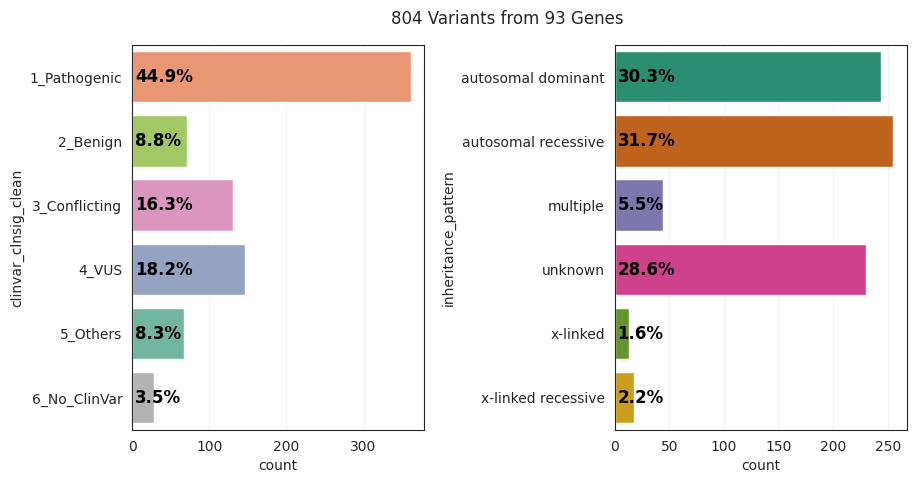

In [10]:
df = scores.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
plot_cat_count_perc(
    scores,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
plt.suptitle(f"{scores.unique('gene_allele').shape[0]} Variants from {scores.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

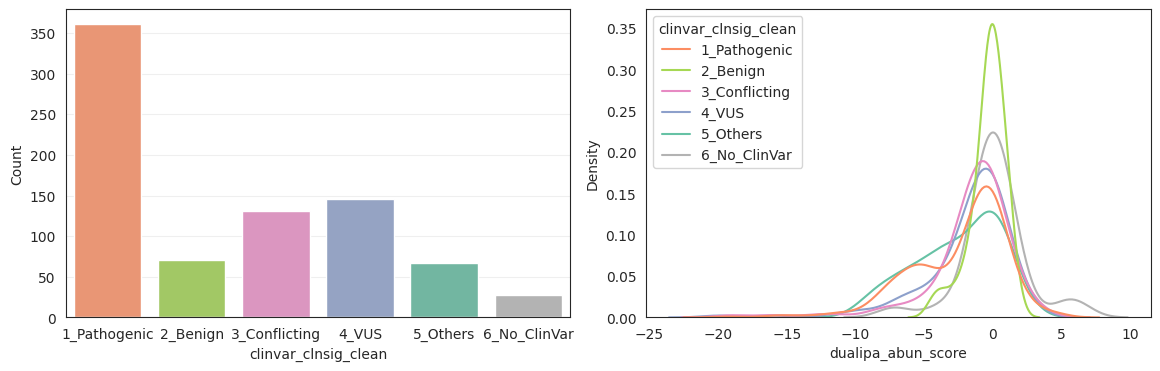

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(
    data=scores.group_by("clinvar_clnsig_clean").
    agg(
        pl.len().alias("Count")
    ).to_pandas(),
    x="clinvar_clnsig_clean", y="Count",
    hue="clinvar_clnsig_clean", palette=palette_dict["clinvar_clnsig_clean"],
    order=hue_order,
    ax=axes[0]
)
axes[0].grid(alpha=0.3, axis='y')

sns.kdeplot(
    data=scores.to_pandas(),
    x="dualipa_abun_score",
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    ax=axes[1],
    palette=palette_dict["clinvar_clnsig_clean"],
    common_norm=False
)
plt.subplots_adjust(wspace=0.15)
plt.show()

#### 1.1.2 All ClinVar variants with somewhat clear annotations (other than "Others") & _ReviewStarStatus>=1_

ClinVar Variants (StarStatus >= 1) Number: 581


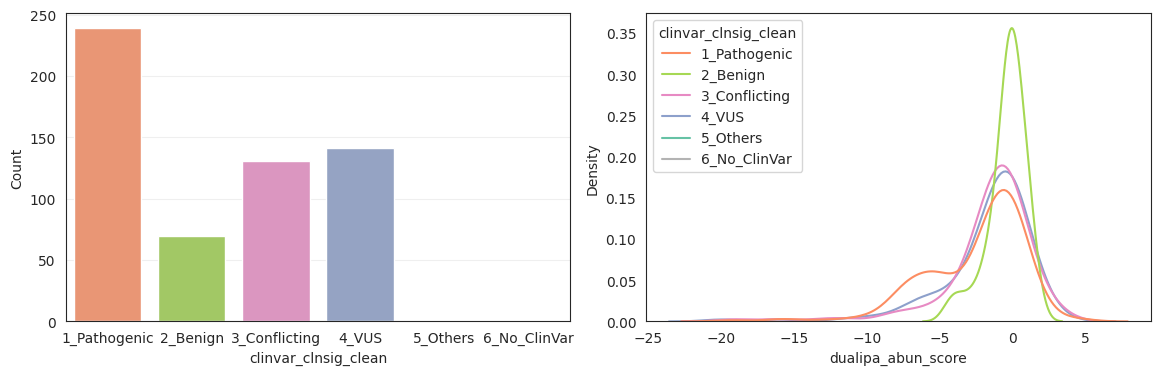

In [12]:
# Define variables to plot
scores_filt = scores.filter(pl.col("StarStatus") >= 1)
print("ClinVar Variants (StarStatus >= 1) Number:", scores_filt.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(
    data=scores_filt.group_by("clinvar_clnsig_clean").
    agg(
        pl.len().alias("Count")
    ).to_pandas(),
    x="clinvar_clnsig_clean", y="Count",
    hue="clinvar_clnsig_clean", 
    palette=palette_dict["clinvar_clnsig_clean"],
    order=hue_order,
    ax=axes[0]
)
axes[0].grid(alpha=0.3, axis='y')

sns.kdeplot(
    data=scores_filt.to_pandas(),
    x="dualipa_abun_score",
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    ax=axes[1],
    palette=palette_dict["clinvar_clnsig_clean"],
    common_norm=False
)
plt.subplots_adjust(wspace=0.15)
plt.show()

### 1.2 All Inheritance_pattern

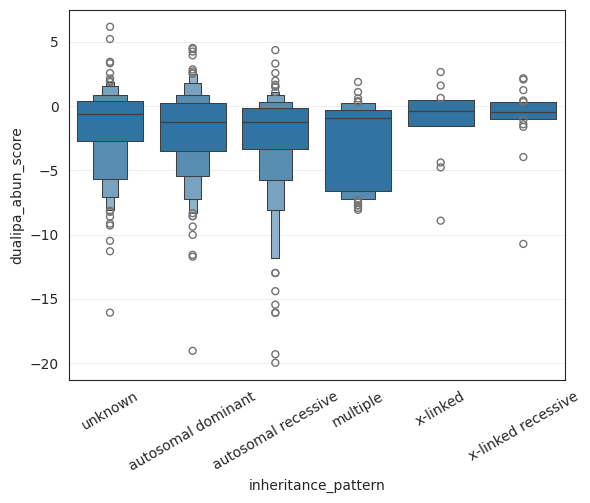

In [13]:
ax = sns.boxenplot(
    data=scores.to_pandas(),
    x="inheritance_pattern",
    y="dualipa_abun_score",
    # hue="inheritance_pattern",
    # hue_order=hue_order,
    #palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
plt.show()

### 1.3 pLDDT + RSA

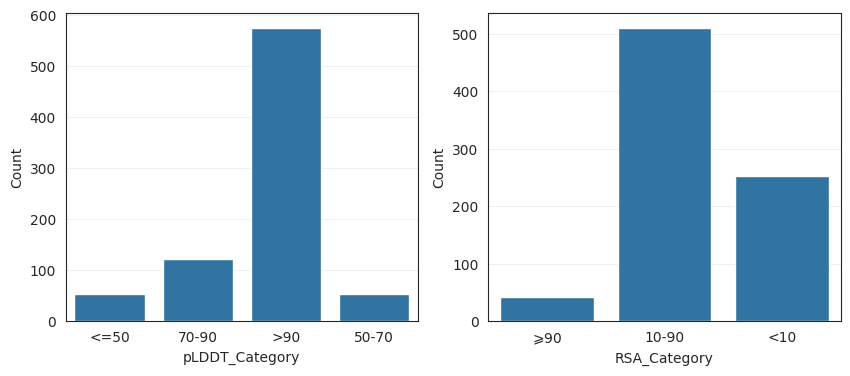

In [14]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.barplot(
    data=scores.group_by("pLDDT_Category").
    agg(
        pl.len().alias("Count")
    ).to_pandas(),
    x="pLDDT_Category", y="Count",
    ax=axes[0]
    # hue="pLDDT_Category", #palette=palette_dict["clinvar_clnsig_clean"]
)
sns.barplot(
    data=scores.group_by("RSA_Category").
    agg(
        pl.len().alias("Count")
    ).to_pandas(),
    x="RSA_Category", y="Count",
    ax=axes[1]
    # hue="pLDDT_Category", #palette=palette_dict["clinvar_clnsig_clean"]
)
axes[0].grid(alpha=0.3, axis='y')
axes[1].grid(alpha=0.3, axis='y')

# ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
plt.show()